# 06. Power grid growth on SP nodes, Joule losses

**Question.** The transmission grid growth model of Emery, Bercegol and Aumaître
(*A Power Grid Growth Model Based on Rural-Urban Differentiation*,
[`TransmissionGrowthModel`](https://github.com/emileemery)) places its urban nodes around
11 hand-placed city centres. What changes if only this spatial part is replaced by the
calibrated SP mixture? The test observable is the Joule losses, the only physical and
published one (RTE reports 3.38 % of the production).

**Data.** RTE grid, injections and voltages from `data/tgm` (TransmissionGrowthModel),
RTE substations of this repository.
**Outputs.** `out/06_powergrid_sp_joule.csv`, `out/06_powergrid_sp_sensitivity.csv`,
`out/06_degrees.csv`, figures `out/06_*.pdf`.
**Paper.** Not in the current version.
**Code.** `src/powergrid_sp.py`.

| | growth model (`ORI`) | here (`SP`) |
|---|---|---|
| urban nodes | exponential decay around 11 centres | points of the SP fractal |
| rural nodes | uniform | uniform background of the mixture |
| urban fraction | `urban_rate = 0.2` | set by the 2PCF calibration |
| connection rules | nearest neighbour / local preferential attachment, second edge with probability q | identical |

Two controls are added: `SP=` (same fractal, urban count of `ORI`) and `RAND` (all nodes
uniform, no city).

> **Status (15 November 2026).** Run again from an empty cache with the common chain, γ averaged over runs and the `DATASETS` values of the November calibration (RTE France: γ = 0.903, m* = 3 547). The text cells quote these outputs.

## Conventions of the common chain (2PCF, fit window, amplitude ratio, SP)

Since the discussion with Charles (November 2026) every notebook uses one chain,
the one of the calibration (`src/calibration.py`, `src/sp_helpers.py`).

**2PCF.** `methods_two_point_correlation.PCF_with_variance`, called here through
`synthesis_utils.compute_2pcf`. Distances in metres, 20 logarithmic edges from the mean
nearest-neighbour distance of the point set to r_max of the dataset, ξ attached to the
upper edge of the bin, Landy-Szalay with split random catalogues (5 × 7 000 points drawn
inside the border), k = 3 repetitions whose spread gives the error bars.

**Fit window and minimum number of pairs.** The power law ξ(r) = (r/r0)^(−γ) is fitted
on the bins 1 to 18 (bin 0 lies below the mean nearest-neighbour distance, the last one
touches r_max), weighted by the spread over the repetitions. One more rule removes
small-r bins: starting from the smallest r, a bin is dropped as long as it holds fewer
than `MIN_PAIRS = 100` data pairs (DD). The first bin with DD ≥ 100 opens the window and
all the bins above it are kept, so the rule only moves the lower bound. Reason: the
relative Poisson noise of a bin is 1/√DD (10 % at 100 pairs). Below that, ξ of the bin
is set by a handful of pairs and can even be negative, and such bins sit at the small r
where the fit has its lever arm on γ. The window actually used is printed by
`su.describe_fit_window(pcf)`.

**γ averaged over runs.** The random catalogues are drawn without a fixed seed, so a
fitted γ moves from one run of the 2PCF to the next (spread 0.01 to 0.13 at N = 3 000,
notebook 10). Every γ of a data set is therefore the mean of the fits of
`N_GAMMA_RUNS = 5` independent runs, each fitted on its own window
(`sp_helpers.average_fits`), and its spread over the runs is given as `gamma_std`:
γ_cal of the calibration, the data 2PCF of `su.load_dataset` and `su.data_2pcf_at_N`,
γ_hi and γ_lo of Δγ, the people 2PCF. The γ of a model is the mean of the fits of its
realisations (one run each).

**Amplitude ratio.** log a = ⟨log ξ_data − log ξ_SP⟩ over the bins of the same window
where both are positive, then n_rand = m_SP (a^(−1/2) − 1). The mean of logs is
symmetric in data and model and is not driven by one bin where ξ_SP is close to zero,
which the former ρ = ⟨ξ_data/ξ_SP⟩ was. γ and a are measured on the same bins.

**SP generation.** `sp_helpers.soneira_peebles_nd` with `dim = 2`: a child that falls
outside the border is drawn again alone (up to 64 times), so the tree keeps its η^L
leaves, is not truncated, and the generation ends whatever the size of the territory.


In [1]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve().parent.parent            # repository root
sys.path.insert(0, str(ROOT / "src"))
import synthesis_utils as su
import powergrid_sp as pg

# Okabe-Ito palette, consistent with notebooks 01-05 (fixed order, never cycled).
C = {"rte": "#000000", "SP": "#0072B2", "ORI": "#D55E00", "RAND": "#999999",
     "ref": "#009E73", "warn": "#CC79A7"}
LBL = {"SP": "SP mixture (this repo)", "ORI": "11 cities (paper)",
       "RAND": "uniform (control)"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "font.size": 10, "axes.axisbelow": True})

SEED = 42
CACHE = ROOT / "out" / "06_cache_cp"      # caches of the common chain (Nov. 2026)
CACHE.mkdir(parents=True, exist_ok=True)
print("cache:", CACHE)

cache: /home/emery/kDrive/Pro/Code/FakeWorld/fake_world_emile-paper-2026/out/06_cache_cp


## 1. Reference: the real RTE grid

Topology (`RTE_weighted.joblib`, lines with length and nominal voltage), net injections
(installed production minus departmental consumption split equally between the
substations, Σ P = 0) and population density of each substation. Losses are normalised
by the installed power (133.9 GW), as in the growth model paper. Since J ∝ P², the
percentage is proportional to the injection level.

In [2]:
ref = pg.load_rte_reference()
G_rte, Ptot = ref["G"], ref["P_prod"].sum()
prod_pool = ref["P_prod"][ref["P_prod"] > 0]          # 2 544 production sites

# population density of the substations, exact join on coordinates
df_rte = pd.read_csv(ROOT / "data" / "clean_transport_dataset" / "France"
                     / "postes-electriques-rte.csv")
ll = np.array([[G_rte.nodes[n]["Longitude"], G_rte.nodes[n]["Latitude"]]
               for n in ref["nodes"]])
d_join, i_join = cKDTree(df_rte[["lng", "lat"]].values).query(ll)
pop_rte = np.clip(df_rte["population_density"].values[i_join], 1.0, None)

q_RTE = pg.q_of(G_rte)
N_RTE = G_rte.number_of_nodes()
print(f"topology   : N = {N_RTE:,} substations, M = {G_rte.number_of_edges():,} lines"
      .replace(",", " "))
print(f"             q = (M−N)/N = {q_RTE:.3f}   L_tot = {pg.total_length_km(G_rte):,.0f} km"
      .replace(",", " "))
print(f"join       : {(d_join < 1e-9).sum()}/{N_RTE} substations matched exactly "
      f"(max distance {d_join.max():.1e}°)")
print(f"injections : installed production {Ptot/1e9:.1f} GW on {len(prod_pool):,} sites, "
      f"Σ P = {ref['P'].sum():.2g} W".replace(",", " "))
print(f"             consumption per substation: median {np.median(ref['P_conso'])/1e6:.0f} MW, "
      f"max {ref['P_conso'].max()/1e6:.0f} MW, CV = "
      f"{ref['P_conso'].std()/ref['P_conso'].mean():.2f}")
volt, cnt = np.unique(ref["volt_mix"], return_counts=True)
print("voltage spectrum:",
      "  ".join(f"{v/1e3:.0f} kV × {c}" for v, c in zip(volt[::-1], cnt[::-1])))

topology   : N = 4 626 substations  M = 6 272 lines
             q = (M−N)/N = 0.356   L_tot = 87 913 km
join       : 4626/4626 substations matched exactly (max distance 0.0e+00°)
injections : installed production 133.9 GW on 2 544 sites  Σ P = 1.3e-05 W
             consumption per substation: median 29 MW, max 119 MW, CV = 0.72
voltage spectrum: 400 kV × 229  225 kV × 1238  150 kV × 47  90 kV × 1296  63 kV × 3382  45 kV × 63  20 kV × 17


## 2. Joule loss estimator

DC load flow of `scripts/build_energy_estimates.py` (TransmissionGrowthModel). Line
resistance R = r(U)ℓ and reactance X = x(U)ℓ from linear fits of the French standard
values,

$$P_{ij} = (\theta_i-\theta_j)\frac{U_{ij}^2}{X_{ij}}, \qquad J_{ij} = R_{ij}\frac{P_{ij}^2}{U_{ij}^2}, \qquad J_\% = 100\frac{\sum J_{ij}}{\sum P_i^{\rm prod}}$$

The next cell checks `powergrid_sp.dc_losses` against the code of the growth model
paper (`grown_graph_pa_flux`) on the same graph.

In [3]:
import contextlib, os

def paper_graph(p_growth=0.5577, seed=0):
    """Runs `grown_graph_pa_flux` of the paper (one realisation)."""
    scripts = (ROOT / "data" / "tgm" / "scripts").resolve()
    src_ = str((ROOT / "data" / "tgm" / "src").resolve())
    if src_ not in sys.path:
        sys.path.insert(0, src_)
    code = (scripts / "build_energy_estimates.py").read_text()
    code = code.split("Nit = 10")[0]        # cut before the multiprocessing block
    cwd = os.getcwd()
    try:
        os.chdir(scripts)
        ns = {"__name__": "not_main"}
        devnull = open(os.devnull, "w")
        with contextlib.redirect_stdout(devnull), contextlib.redirect_stderr(devnull):
            exec(compile(code, "build_energy_estimates.py", "exec"), ns)
            import random as _r
            _r.seed(seed); np.random.seed(seed)
            G = ns["grown_graph_pa_flux"](p_growth=p_growth,
                                         preferential_attachment=True)
    finally:
        os.chdir(cwd)
    return G, ns

_cache_v = CACHE / "verif_paper.joblib"
if _cache_v.exists():
    J_paper, J_ours, n_p, m_p, L_p = joblib.load(_cache_v)
else:
    import networkx as nx
    t0 = time.time()
    Gp, ns = paper_graph()
    J_paper = 100 * sum(nx.get_edge_attributes(Gp, "imped_weight_min").values()) / Ptot
    H = nx.Graph()
    for u, v, d in Gp.edges(data=True):
        H.add_edge(u, v, length=max(d["length_in_m"], 10.0), time=d["time"],
                   Tension=float(d["Voltage"]))
    P_p = np.array([Gp.nodes[n]["Production_MW"] for n in H.nodes()]) * 1e6
    U_p = np.array([d["Tension"] for _, _, d in H.edges(data=True)])
    J_ours = pg.loss_pct(H, P_p, Ptot, U_p, voltage_rule="given")
    n_p, m_p, L_p = Gp.number_of_nodes(), Gp.number_of_edges(), pg.total_length_km(H)
    joblib.dump((J_paper, J_ours, n_p, m_p, L_p), _cache_v)
    print(f"(computed in {time.time()-t0:.0f} s)")

print(f"realisation of the paper: N = {n_p}, M = {m_p}, L_tot = {L_p:,.0f} km"
      .replace(",", " "))
print(f"  losses, code of the paper        : {J_paper:.3f} %")
print(f"  losses, powergrid_sp.dc_losses   : {J_ours:.3f} %")
print(f"  relative gap                     : {abs(J_ours-J_paper)/J_paper:.1e}")

realisation of the paper: N = 4626  M = 7222  L_tot = 87 399 km
  losses, code of the paper        : 3.753 %
  losses, powergrid_sp.dc_losses   : 3.753 %
  relative gap                     : 2.0e-13


### Three choices that set the result

| choice | wrong | right | effect on the real grid |
|---|---|---|---|
| susceptance | `b = 1/X` | `b = U²/X` (per unit) | 17 % → 4.7 % |
| voltage assignment | random, or longest line = highest voltage | by flow rank (iterated) | ×6 to ×26 |
| injection level | implicit | installed power | J_% ∝ P |

The growth model pops a sorted voltage queue, so the first edges get 400 kV. This only
works because the injections are also sorted by node index. The flow-rank rule does not
depend on any creation order and is the default here.

In [4]:
# --- pitfall 1: the susceptance -----------------------------------------------
import scipy.sparse as spmat, scipy.sparse.linalg as spla
import networkx as nx

def losses_wrong_susceptance(G, P, Ptot):
    """The same computation with b = 1/X instead of U²/X (single-voltage grid assumed)."""
    nodes = list(G.nodes()); idx = {n: i for i, n in enumerate(nodes)}
    I = np.array([idx[u] for u, _ in G.edges()])
    Jn = np.array([idx[v] for _, v in G.edges()])
    L = np.array([d["length"] for _, _, d in G.edges(data=True)])
    U = np.array([d["Tension"] for _, _, d in G.edges(data=True)], dtype=float)
    X = pg.x_lin(U) * L; b = 1.0 / X
    B = spmat.csr_matrix((np.r_[b, b, -b, -b],
                          (np.r_[I, Jn, I, Jn], np.r_[I, Jn, Jn, I])),
                         shape=(len(nodes),) * 2)
    th = np.zeros(len(nodes)); th[1:] = spla.spsolve(B[1:, 1:].tocsc(), P[1:])
    f = (th[I] - th[Jn]) / X
    return 100 * (pg.r_lin(U) * L * f ** 2 / U ** 2).sum() / Ptot

print("real RTE grid, real injections, real voltages")
print(f"  b = 1/X   (single voltage, wrong) : "
      f"{losses_wrong_susceptance(G_rte, ref['P'], Ptot):6.2f} %")
print(f"  b = U²/X  (per-unit, correct)     : "
      f"{pg.loss_pct(G_rte, ref['P'], Ptot, ref['volt_mix'], voltage_rule='given'):6.2f} %")

print("\nreal RTE grid, effect of the voltage assignment rule")
print("  (the voltage spectrum is the same in all cases, the 6 272 real lines)")
for rule, txt in [("given", "real RTE voltages"),
                  ("flow", "by flow rank (default)"),
                  ("length", "longest = highest"),
                  ("random", "at random")]:
    print(f"  {txt:<32s} : "
          f"{pg.loss_pct(G_rte, ref['P'], Ptot, ref['volt_mix'], voltage_rule=rule):6.2f} %")
print(f"\n  value published by RTE             : {pg.RTE_PUBLISHED_LOSS_PCT:6.2f} %")

real RTE grid, real injections, real voltages
  b = 1/X   (single voltage, wrong) :  16.96 %
  b = U²/X  (per-unit, correct)     :   4.74 %

real RTE grid, effect of the voltage assignment rule
  (the voltage spectrum is the same in all cases, the 6 272 real lines)
  real RTE voltages                :   4.74 %
  by flow rank (default)           :   3.20 %
  longest = highest                :  19.44 %
  at random                        :  83.68 %

  value published by RTE             :   3.38 %


On the real topology the estimator gives 4.7 % with the real voltages and 3.2 % with the
flow-rank rule, around the published 3.38 %. The models are compared with these two
values (same estimator), not with the published one.

## 3. Four point clouds

- `SP`: `synthesis_utils.build_sp_mixture(..., return_labels=True)` calibrated on "RTE
  France" (η = 6, γ = 0.90), in Lambert-93. The tree is drawn by the N-dimensional
  generator with dim = 2 (child-by-child rejection at the border), and the background is
  sized by log a = ⟨log ξ_data − log ξ_SP⟩ on the fit window of the data.
- `SP=`: same tree, but the urban count is the one drawn by `ORI` at the same seed. The
  amplitude ratio a is not used, so this variant does not depend on its estimate.
- `ORI`: 11 cities of the growth model.
- `RAND`: uniform control.

The calibrated urban fraction is 0.30 ± 0.04, against 0.20 in `ORI`. It is not m*/N,
which sizes the fractal before thinning. (The former ρ = ⟨ξ_data/ξ_SP⟩ went through
`np.interp(..., left=0.0)`, which set to zero the fractal bins below the range of the
data and underestimated ρ by about 2. The log a of the common chain has no such bias:
only the bins of the fit window where both ξ are positive enter the mean.)


In [5]:
ds = su.DATASETS["RTE France"]
t0 = time.time()
ld = su.load_dataset(ds, verbose=False)
print(f"dataset loaded in {time.time()-t0:.1f} s, N = {ld['N_real']:,} substations, "
      f"γ = {ld['gamma_fit']:.3f}".replace(",", " "))

C["SP20"] = "#56B4E9"                      # Okabe-Ito sky blue, parent of the SP blue
LBL["SP20"] = "SP with imposed threshold"
MODELS = ("SP", "SP20", "ORI", "RAND")     # display order, everywhere in the notebook

BUILDERS = {
    "SP":   lambda s: pg.nodes_sp_mixture(ds, ld, N_RTE, seed=s),
    "ORI":  lambda s: pg.nodes_cities(ld, N_RTE, seed=s),
    "RAND": lambda s: pg.nodes_uniform(ld, N_RTE, seed=s),
}
N_RUNS = 8

_cache_pos = CACHE / f"positions_N{N_RTE}_R{N_RUNS}_M{len(MODELS)}.joblib"
if _cache_pos.exists():
    POS = joblib.load(_cache_pos)
    print("positions: loaded from cache")
else:
    t0 = time.time()
    POS = {m: [BUILDERS[m](s) for s in range(N_RUNS)] for m in BUILDERS}
    # SP=: same fractal as SP at equal seed, but imposed number of structured nodes,
    #      the one just drawn by `nodes_cities`, seed by seed.
    POS["SP20"] = [pg.nodes_sp_mixture_fixed(ds, ld, N_RTE,
                                             int(POS["ORI"][s][1].sum()), seed=s)
                   for s in range(N_RUNS)]
    joblib.dump(POS, _cache_pos)
    print(f"positions: {len(MODELS)*N_RUNS} clouds generated in {time.time()-t0:.0f} s")

print(f"\n{'seed':>7s}" + "".join(f"{LBL[m]:>28s}" for m in MODELS[:3]))
for s in range(N_RUNS):
    print(f"{s:>7d}" + "".join(f"{int(POS[m][s][1].sum()):>28d}" for m in MODELS[:3]))
print()
for m in MODELS[:3]:
    f = np.array([iu.mean() for _, iu in POS[m]])
    note = {"SP": "← emergent (2PCF calibration)", "SP20": "← imposed = the one of ORI",
            "ORI": "← set (urban_rate = 0.2)"}[m]
    print(f"urban fraction {LBL[m]:<26s} : {f.mean():.3f} ± {f.std():.3f}  {note}")
print(f"m*/N of the dataset                         : {ds['m_star']/ds['N']:.3f}  "
      f"← something else, see above")

dataset loaded in 71.8 s  N = 4 932 substations  γ = 0.914


positions: 32 clouds generated in 7 s

   seed      SP mixture (this repo)   SP with imposed threshold           11 cities (paper)
      0                        1403                         871                         871
      1                        1330                         913                         913
      2                        1645                         924                         924
      3                        1254                         918                         918
      4                        1509                         965                         965
      5                        1279                         954                         954
      6                        1077                         949                         949
      7                        1524                         893                         893

urban fraction SP mixture (this repo)     : 0.298 ± 0.037  ← emergent (2PCF calibration)
urban fraction SP with imposed threshold  :

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(18.5, 4.4))
bnd = ld["gdf_edge"].boundary

ax = axes[0]
bnd.plot(ax=ax, color="0.3", lw=0.6)
ax.scatter(ld["xy_metric"][:, 0], ld["xy_metric"][:, 1], s=1.2, c=C["rte"], alpha=.55,
           linewidths=0)
ax.set_title(f"data, RTE substations\n{ld['N_real']:,} points".replace(",", " "),
             fontsize=10)

for ax, m in zip(axes[1:], MODELS):
    xy, iu = POS[m][0]
    bnd.plot(ax=ax, color="0.3", lw=0.6)
    ax.scatter(xy[~iu, 0], xy[~iu, 1], s=1.2, c="0.75", alpha=.6, linewidths=0)
    ax.scatter(xy[iu, 0], xy[iu, 1], s=1.6, c=C[m], alpha=.8, linewidths=0)
    ax.set_title(f"{LBL[m]}\n{iu.sum():,} urban / {len(xy):,}".replace(",", " "),
                 fontsize=10)

for ax in axes:
    ax.set_aspect("equal"); ax.axis("off")
fig.suptitle("The four spatial models, urban nodes in colour, random background in grey.\n"
             "SP and SP= share the same fractal, only the number of kept points changes.",
             fontsize=11, y=1.06)
plt.tight_layout()
fig.savefig(ROOT / "out" / "06_clouds.pdf", bbox_inches="tight")
plt.show()

<Figure size 2035x484 with 5 Axes>

(2PCF computed in 228 s)


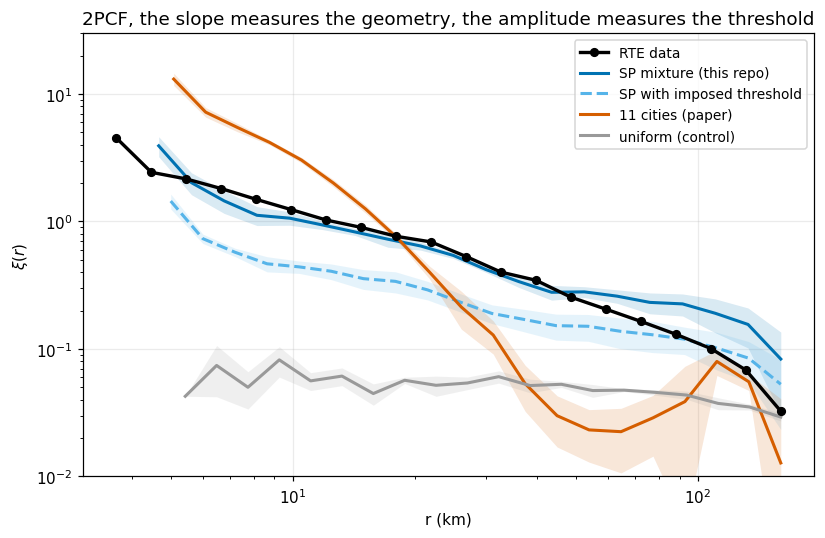

data 2PCF: fit window: bins 1..18 (4.47-131.2 km), 0 small-r bin(s) dropped (DD < 100)
                                   γ  ± (4 real.)      a (mod/data)
SP mixture (this repo)         0.820        0.159              1.07
SP with imposed threshold      0.704        0.135              0.51
11 cities (paper)              1.909        0.073              0.68
uniform (control)              0.285        0.016              0.10
RTE data                       0.914        0.013              1.00   (data: mean of 5 runs of the 2PCF)

(ξ ≤ 0 masked: beyond about 100 km the correlation becomes negative for all models, this is the effect of the border of the territory.)


In [7]:
# 2PCF: does the SP mixture reproduce the correlation of the RTE substations?
_cache_pcf = CACHE / f"pcf_models_M{len(MODELS)}_gruns.joblib"
if _cache_pcf.exists():
    PCF = joblib.load(_cache_pcf)
else:
    t0 = time.time()
    PCF = {}
    for m in MODELS:
        xis, gs, r_ref = [], [], None
        for s in range(4):
            xy_n, _ = su.normalize_coords(POS[m][s][0], ld["bounds"])
            pcf_k = su.compute_2pcf(xy_n, ld, full=True)  # common chain, r in metres
            r_k, xi_k = pcf_k["r"], pcf_k["xi"]
            gs.append(np.nan if pcf_k["gamma"] is None else pcf_k["gamma"])
            if r_ref is None:                            # the edges start at the mean NN
                r_ref = r_k                              # distance, which changes with
            xis.append(su._align_xi(r_k, xi_k, r_ref))   # the cloud: align on the first
        # gamma of a model: mean of the fits of the 4 realisations (one 2PCF run each)
        PCF[m] = (r_ref, np.nanmean(xis, axis=0), np.nanstd(xis, axis=0), np.array(gs))
    joblib.dump(PCF, _cache_pcf)
    print(f"(2PCF computed in {time.time()-t0:.0f} s)")

fig, ax = plt.subplots(figsize=(7.6, 5.0))
ax.plot(ld["r_data"] / 1e3, np.where(ld["xi_data"] > 0, ld["xi_data"], np.nan),
        "o-", color=C["rte"], lw=2.2, ms=5, label="RTE data", zorder=5)
for m in MODELS:
    r_m, xi_m, xis_m, _ = PCF[m]
    pos = xi_m > 0                          # log scale: ξ ≤ 0 is masked
    ls = "--" if m == "SP20" else "-"
    ax.plot((r_m / 1e3)[pos], xi_m[pos], ls, color=C[m], lw=2, label=LBL[m])
    ax.fill_between((r_m / 1e3)[pos],
                    np.clip(xi_m - xis_m, 1e-3, None)[pos], (xi_m + xis_m)[pos],
                    color=C[m], alpha=.15, lw=0)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_ylim(1e-2, 3e1)
ax.set_xlabel("r (km)"); ax.set_ylabel(r"$\xi(r)$")
ax.set_title("2PCF, the slope measures the geometry, the amplitude measures the threshold")
ax.legend(fontsize=9)
plt.tight_layout()
fig.savefig(ROOT / "out" / "06_2pcf.pdf", bbox_inches="tight")
plt.show()

# γ: the shape. a = exp⟨log ξ_mod − log ξ_data⟩: the level, on the fit window of the
# data (bins 1..18 minus the small-r bins with fewer than MIN_PAIRS pairs).
print("data 2PCF:", su.describe_fit_window(ld["pcf_data"]))
w = ld["pcf_data"]["fit_info"]
print(f"{'':<28s}{'γ':>8s}{'± (4 real.)':>13s}{'a (mod/data)':>18s}")
for m in MODELS:
    r_m, xi_m, _, gs = PCF[m]
    g, g_sd = np.nanmean(gs), np.nanstd(gs, ddof=1)
    xd = np.interp(np.log10(r_m), np.log10(ld["r_data"]),
                   np.nan_to_num(ld["xi_data"]), left=np.nan, right=np.nan)
    sel = (np.isfinite(xd) & (xd > 0) & (xi_m > 0)
           & (r_m >= w["r_lo"] * 0.999) & (r_m <= w["r_hi"] * 1.001))
    print(f"{LBL[m]:<28s}{g:>8.3f}{g_sd:>13.3f}{np.exp(np.mean(np.log(xi_m[sel] / xd[sel]))):>18.2f}")
gd = ld["pcf_data"]
print(f"{'RTE data':<28s}{gd['gamma']:>8.3f}{gd['gamma_std']:>13.3f}{1.0:>18.2f}"
      f"   (data: mean of {gd['n_runs']} runs of the 2PCF)")
print("\n(ξ ≤ 0 masked: beyond about 100 km the correlation becomes negative for all "
      "models, this is the effect of the border of the territory.)")

The SP mixture is the cloud closest to the data, in slope (γ = 0.82 against 0.91) and in
amplitude (a = 1.07): the log a calibration gives an urban fraction of 0.30 ± 0.04 and
the right level of ξ. With the threshold imposed at 0.20 the amplitude falls to a = 0.51,
as ξ_mix = f² ξ_SP predicts ((0.200/0.298)² = 0.45), and the fitted slope is flatter
(0.70). The 11 cities give γ = 1.91 (too few, too compact clusters) and the uniform
control 0.29 (border effect only). With the former chain the ρ calibration gave
f = 0.17 and a mixture at half the amplitude of the data.


## 4. Growth

`grow_network` follows the rules of `grown_graph_pref_attach_poly`. A rural node links to
its nearest placed neighbour, an urban node to the highest-degree node among its 3
nearest neighbours, and a second edge is added with probability q. All distances are
metric here (the original code compares rural nodes in degrees, which biases the
neighbour search towards north-south).

In [8]:
Q_SWEEP = np.array([0.05, 0.15, 0.25, q_RTE, 0.45, 0.5577, 0.70, 0.85])
Q_PAPER = 0.5577          # q of the paper: counts multiple circuits (7 206 circuits)

_cache_net = CACHE / f"networks_N{N_RTE}_R{N_RUNS}_M{len(MODELS)}.joblib"
if _cache_net.exists():
    NETS = joblib.load(_cache_net)
    print("networks: loaded from cache")
else:
    t0 = time.time()
    NETS = {m: {round(float(q), 4): [pg.grow_network(POS[m][s][0], POS[m][s][1],
                                                    float(q), seed=s)
                                     for s in range(N_RUNS)]
                for q in Q_SWEEP}
            for m in MODELS}
    joblib.dump(NETS, _cache_net)
    print(f"networks: {len(MODELS)*len(Q_SWEEP)*N_RUNS} graphs in {time.time()-t0:.0f} s")

qk = round(float(q_RTE), 4)
print(f"\nstructure at q = q_RTE = {q_RTE:.3f}  (mean ± σ over {N_RUNS} draws)")
print(f"{'':<28s}{'L_tot (km)':>18s}{'⟨k⟩':>8s}{'k_max':>8s}"
      f"{'% dead ends':>15s}{'median edge (km)':>18s}")
rows_struct = {}
for m in MODELS:
    Gs = NETS[m][qk]
    L = [pg.total_length_km(G) for G in Gs]
    k = [np.mean([d for _, d in G.degree()]) for G in Gs]
    kmax = [max(d for _, d in G.degree()) for G in Gs]
    dead = [np.mean([d == 1 for _, d in G.degree()]) for G in Gs]
    emed = [np.median([d["length"] for _, _, d in G.edges(data=True)]) / 1e3 for G in Gs]
    rows_struct[m] = dict(L=np.mean(L), Ls=np.std(L), k=np.mean(k), kmax=np.mean(kmax),
                          dead=np.mean(dead), emed=np.mean(emed))
    print(f"{LBL[m]:<28s}{np.mean(L):>11,.0f} ±{np.std(L):>5,.0f}{np.mean(k):>8.2f}"
          f"{np.mean(kmax):>8.0f}{100*np.mean(dead):>14.1f}%{np.mean(emed):>18.1f}"
          .replace(",", " "))
deg_rte = np.array([d for _, d in G_rte.degree()])
elen_rte = np.array([d["length"] for _, _, d in G_rte.edges(data=True)])
rows_struct["RTE"] = dict(L=pg.total_length_km(G_rte), Ls=0.0, k=deg_rte.mean(),
                          kmax=deg_rte.max(), dead=(deg_rte == 1).mean(),
                          emed=np.median(elen_rte) / 1e3)
r = rows_struct["RTE"]
print(f"{'real RTE grid':<28s}{r['L']:>11,.0f}{'':>6s}{r['k']:>8.2f}{r['kmax']:>8.0f}"
      f"{100*r['dead']:>14.1f}%{r['emed']:>18.1f}".replace(",", " "))

networks: 256 graphs in 291 s

structure at q = q_RTE = 0.356  (mean ± σ over 8 draws)
                                    L_tot (km)     ⟨k⟩   k_max    % dead ends  median edge (km)
SP mixture (this repo)           73 248 ±1 117    2.72      23          32.2%               7.8
SP with imposed threshold        76 310 ±  853    2.72      22          29.8%               8.4
11 cities (paper)                73 459 ±  856    2.72      26          29.9%               8.2
uniform (control)                78 124 ±1 140    2.72      15          26.2%               8.9
real RTE grid                    87 913          2.71      24          29.0%               9.3


In [9]:
# ---------------------------------------------------------------------------
# The "standard growth model" of the paper (fig. 6), over the whole q range.
# It is neither re-implemented nor adapted: `grown_graph_pa_flux` is run as it
# is, and its per-edge losses are taken.
#
# This is needed because the model of the paper carries **three** choices
# locked to each other, which cannot be taken separately:
#   1. injections sorted by node index               (`queue_power.pop()`)
#   2. voltages sorted by creation order              (`queue_voltage.pop()`)
#   3. its own voltage spectrum, regenerated with the proportions
#      taux63/taux90/taux225 on int(N_edges)+1 slots with a 5 sigma margin,
#      so the last 63 kV slots are never popped.
#
# Checked on one realisation at q = 0.5577 (the four numbers below all come
# from the **same** graph, the one of the paper):
#   code of the paper ............................................. 3.753 %
#   dc_losses, sorted P, spectrum of the paper, voltage_rule="time" 3.753 %  ✓
#   dc_losses, sorted P, REAL spectrum (6 272 lines),       "time" . 4.539 %
#   dc_losses, sorted P, spectrum of the paper,             "flow" . 2.174 %
# Taking one queue without the other, or the real spectrum instead of its own,
# changes the result by a factor of about 2, hence the choice to run its code.
# ---------------------------------------------------------------------------
import multiprocessing as mp

_PAPER_NS = {}


def _paper_ns():
    """Namespace of the script of the paper, loaded once per process."""
    if "ns" not in _PAPER_NS:
        scripts = (ROOT / "data" / "tgm" / "scripts").resolve()
        src_ = str((ROOT / "data" / "tgm" / "src").resolve())
        if src_ not in sys.path:
            sys.path.insert(0, src_)
        code = (scripts / "build_energy_estimates.py").read_text().split("Nit = 10")[0]
        cwd = os.getcwd()
        try:
            os.chdir(scripts)
            ns = {"__name__": "not_main"}
            with open(os.devnull, "w") as dn, contextlib.redirect_stdout(dn), \
                 contextlib.redirect_stderr(dn):
                exec(compile(code, "build_energy_estimates.py", "exec"), ns)
        finally:
            os.chdir(cwd)
        _PAPER_NS["ns"] = ns
    return _PAPER_NS["ns"]


def _paper_one(args):
    """One realisation: per-edge losses, voltage and length of each edge, degrees."""
    import random as _r
    import networkx as nx
    q, seed = args
    ns = _paper_ns()
    _r.seed(seed); np.random.seed(seed)
    with open(os.devnull, "w") as dn, contextlib.redirect_stdout(dn), \
         contextlib.redirect_stderr(dn):
        G = ns["grown_graph_pa_flux"](p_growth=float(q), preferential_attachment=True)
    Jd = nx.get_edge_attributes(G, "imped_weight_min")
    e = list(Jd)
    return (round(float(q), 4), seed,
            dict(J=np.array([Jd[k] for k in e], dtype=float),
                 U=np.array([G.edges[k]["Voltage"] for k in e], dtype=float),
                 L=np.array([G.edges[k]["length_in_m"] for k in e], dtype=float),
                 deg=np.array([d for _, d in G.degree()], dtype=int)))


_cache_gm = CACHE / "paper_growth_model.joblib"
if _cache_gm.exists():
    PAPER = joblib.load(_cache_gm)
    print("model of the paper: loaded from cache")
else:
    t0 = time.time()
    jobs = [(float(q), s) for q in Q_SWEEP for s in range(N_RUNS)]
    with mp.Pool(min(12, mp.cpu_count())) as pool:      # about 2 min on 12 cores
        PAPER = {(q, s): d for q, s, d in pool.map(_paper_one, jobs, chunksize=1)}
    joblib.dump(PAPER, _cache_gm, compress=3)
    print(f"model of the paper: {len(jobs)} realisations in {time.time()-t0:.0f} s")

# total losses, in % of the installed power, the curve of fig. 6
J_GM = {}
for q in Q_SWEEP:
    k = round(float(q), 4)
    v = [100 * PAPER[(k, s)]["J"].sum() / Ptot for s in range(N_RUNS)]
    J_GM[k] = (float(np.mean(v)), float(np.std(v)))

# check of the port: our `grow_network` ("11 cities" model) against the code of
# the paper, at q = q_RTE, on the structure observables of section 4
_gL = [PAPER[(qk, s)]["L"].sum() / 1e3 for s in range(N_RUNS)]
_gd = [PAPER[(qk, s)]["deg"] for s in range(N_RUNS)]
_ge = [np.median(PAPER[(qk, s)]["L"]) / 1e3 for s in range(N_RUNS)]
print(f"\nport of the 11-city model, our `grow_network` against the code of the paper"
      f"   (q = q_RTE, {N_RUNS} draws)")
print(f"{'':<28s}{'L_tot (km)':>18s}{'⟨k⟩':>8s}{'k_max':>8s}"
      f"{'% dead ends':>15s}{'median edge (km)':>18s}")
r = rows_struct["ORI"]
print(f"{'  re-implementation':<28s}{r['L']:>11,.0f} ±{r['Ls']:>5,.0f}{r['k']:>8.2f}"
      f"{r['kmax']:>8.0f}{100*r['dead']:>14.1f}%{r['emed']:>18.1f}".replace(",", " "))
print(f"{'  code of the paper':<28s}{np.mean(_gL):>11,.0f} ±{np.std(_gL):>5,.0f}"
      f"{np.mean([d.mean() for d in _gd]):>8.2f}{np.mean([d.max() for d in _gd]):>8.0f}"
      f"{100*np.mean([(d == 1).mean() for d in _gd]):>14.1f}%{np.mean(_ge):>18.1f}"
      .replace(",", " "))
print(f"\nlosses of the model of the paper (its code, its two queues):")
print(f"  at q = q_RTE   = {q_RTE:.4f} : {J_GM[qk][0]:.2f} ± {J_GM[qk][1]:.2f} %")
_kp = round(float(Q_PAPER), 4)
print(f"  at q = q paper = {Q_PAPER:.4f} : {J_GM[_kp][0]:.2f} ± {J_GM[_kp][1]:.2f} %"
      f"   (published by RTE: {pg.RTE_PUBLISHED_LOSS_PCT:.2f} %)")

model of the paper: loaded from cache

port of the 11-city model, our `grow_network` against the code of the paper   (q = q_RTE, 8 draws)
                                    L_tot (km)     ⟨k⟩   k_max    % dead ends  median edge (km)
  re-implementation              73 459 ±  856    2.72      26          29.9%               8.2
  code of the paper              73 087 ±  767    2.72      22          29.3%               8.1

losses of the model of the paper (its code, its two queues):
  at q = q_RTE   = 0.3558 : 4.66 ± 0.38 %
  at q = q paper = 0.5577 : 3.47 ± 0.27 %   (published by RTE: 3.38 %)


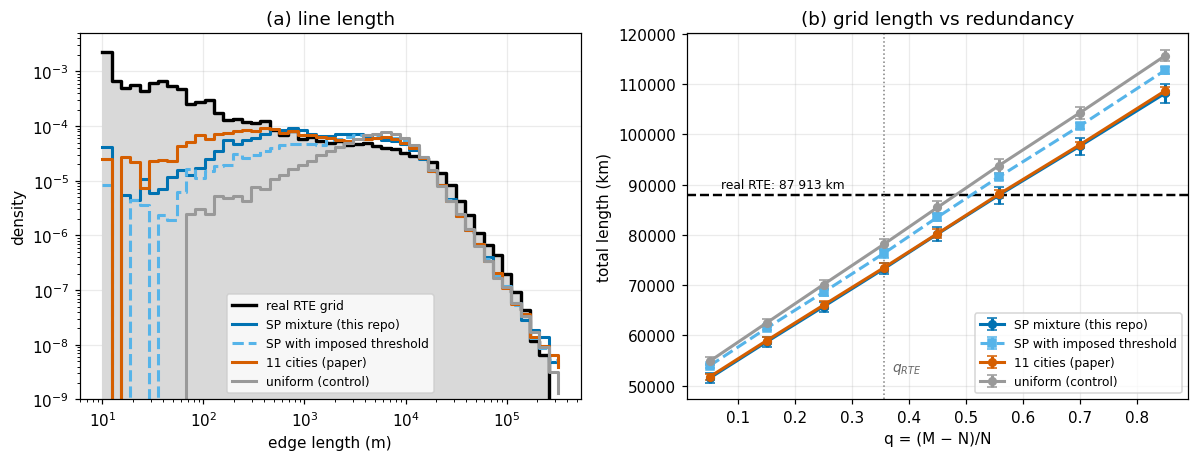

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

# (a) edge lengths
ax = axes[0]
lb = np.logspace(1, 5.6, 51); lx = lb[:-1]
ax.fill_between(lx, np.histogram(elen_rte, bins=lb, density=True)[0], 1e-10,
                step="post", color="0.85", lw=0)
ax.step(lx, np.histogram(elen_rte, bins=lb, density=True)[0], where="post",
        color=C["rte"], lw=2.2, label="real RTE grid")
for m in MODELS:
    e = np.concatenate([[d["length"] for _, _, d in G.edges(data=True)]
                        for G in NETS[m][qk]])
    ax.step(lx, np.histogram(e, bins=lb, density=True)[0], where="post",
            color=C[m], lw=2, ls="--" if m == "SP20" else "-", label=LBL[m])
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-9, 5e-3)
ax.set_xlabel("edge length (m)"); ax.set_ylabel("density")
ax.set_title("(a) line length"); ax.legend(fontsize=8)

# (b) total length vs q
ax = axes[1]
for m in MODELS:
    st = [[pg.total_length_km(G) for G in NETS[m][round(float(q), 4)]] for q in Q_SWEEP]
    ax.errorbar(Q_SWEEP, [np.mean(v) for v in st], yerr=[np.std(v) for v in st],
                fmt="s--" if m == "SP20" else "o-", color=C[m], lw=2, ms=5, capsize=3,
                label=LBL[m])
L_rte = pg.total_length_km(G_rte)
ax.axhline(L_rte, color=C["rte"], lw=1.6, ls="--")
ax.annotate(f"real RTE: {L_rte:,.0f} km".replace(",", " "), xy=(0.07, L_rte),
            xytext=(0.07, L_rte * 1.015), fontsize=8, color=C["rte"])
ax.axvline(q_RTE, color="0.5", lw=1, ls=":")
ax.annotate("$q_{RTE}$", xy=(q_RTE, 5.3e4), xytext=(q_RTE + .015, 5.3e4), fontsize=9,
            color="0.4")
ax.set_xlabel("q = (M − N)/N"); ax.set_ylabel("total length (km)")
ax.set_title("(b) grid length vs redundancy"); ax.legend(fontsize=8, loc="lower right")

plt.tight_layout()
fig.savefig(ROOT / "out" / "06_topology.pdf", bbox_inches="tight")
plt.show()

At q = q_RTE the four models have the same mean degree as RTE (2.72 against 2.71), a
median edge of 7.8 to 8.9 km (9.3 km for RTE) and 26 to 32 % of dead ends (29 %).
Without cities there is no hub (k_max 15 against 22 to 26). All models have fewer very
short links than RTE (left panel). The total length is 11 to 17 % below RTE at q_RTE and
reaches it near q = 0.56, the q of the growth model paper, which counts the circuits.


### 4.1 Degree distributions

At N = 4 626 any goodness-of-fit test rejects everything, so the χ² is given for
reference only. We use the total variation distance TV = ½ Σ|P(k) − Q(k)| (fraction of
nodes that would change degree class), compared with the noise floor, the mean TV
between two draws of the same model. The growth model is run with its own code, which
also checks our re-implementation.

degree distribution P(k), in % of the nodes   (q = q_RTE, 8 draws)

                                      1      2      3      4      5      6      7      8     ≥9     ⟨k⟩
SP mixture (this repo)             32.2   28.9   15.7    9.0    5.3    3.1    1.9    1.2    2.6    2.72
SP with imposed threshold          29.8   30.1   16.2    9.9    5.6    3.2    1.8    1.1    2.2    2.72
11 cities (paper)                  29.9   29.5   16.9    9.8    5.5    3.5    2.0    1.2    1.8    2.72
uniform (control)                  26.2   30.5   18.3   11.2    6.3    3.4    1.9    0.9    1.2    2.72
standard growth model (paper)      29.3   29.5   17.0   10.1    5.9    3.4    1.9    1.0    1.9    2.72
real RTE                           29.0   30.4   25.2    4.8    2.5    1.6    1.6    1.4    3.5    2.71

                                    TV(model, RTE)  intra noise     ratio   χ² (9 dof)          p
SP mixture (this repo)               0.1213 ±0.0046       0.0214      5.7×          524   3.4e-107
SP wit

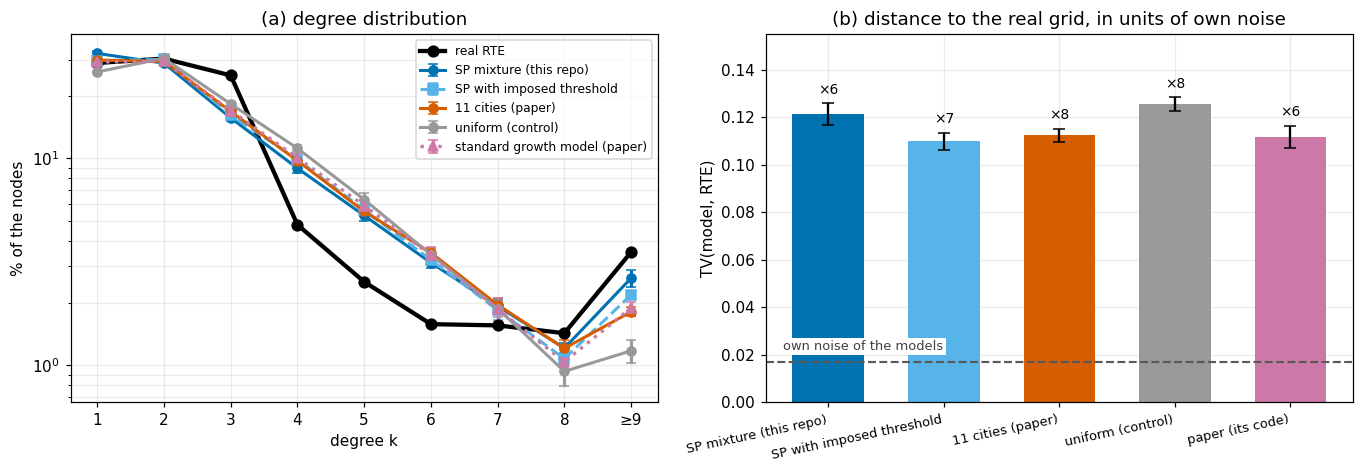

In [11]:
import itertools
from scipy import stats

KMAX = 9                                   # classes 1, 2, … 8, ≥9
KLAB = [str(k) for k in range(1, KMAX)] + [f"≥{KMAX}"]


def deg_pmf(deg):
    d = np.clip(np.asarray(deg), 1, KMAX)
    return np.bincount(d, minlength=KMAX + 1)[1:].astype(float) / len(d)


def tv(a, b):
    """Total variation distance between two discrete distributions."""
    return 0.5 * np.abs(a - b).sum()


DEG = {m: [np.array([d for _, d in G.degree()]) for G in NETS[m][qk]] for m in MODELS}
DEG["GM"] = [PAPER[(qk, s)]["deg"] for s in range(N_RUNS)]
DEG["RTE"] = [np.array([d for _, d in G_rte.degree()])]
PK = {k: np.array([deg_pmf(d) for d in v]) for k, v in DEG.items()}
DKEYS = list(MODELS) + ["GM"]
DLBL = dict(LBL, GM="standard growth model (paper)", RTE="real RTE")
C["GM"] = C["warn"]        # the model of the paper: Okabe-Ito pink, black stays for RTE

print(f"degree distribution P(k), in % of the nodes   (q = q_RTE, {N_RUNS} draws)\n")
print(f"{'':<32s}" + "".join(f"{l:>7s}" for l in KLAB) + f"{'⟨k⟩':>8s}")
for k in DKEYS + ["RTE"]:
    mu = PK[k].mean(0)
    print(f"{DLBL[k]:<32s}" + "".join(f"{100*x:>7.1f}" for x in mu)
          + f"{np.mean([d.mean() for d in DEG[k]]):>8.2f}")

# noise floor: TV between two draws of the same model
intra = {m: (lambda v: (np.mean(v), np.std(v)))(
             [tv(PK[m][i], PK[m][j])
              for i, j in itertools.combinations(range(N_RUNS), 2)])
         for m in DKEYS}

print(f"\n{'':<32s}{'TV(model, RTE)':>18s}{'intra noise':>13s}"
      f"{'ratio':>10s}{'χ² (9 dof)':>13s}{'p':>11s}")
n_rte = len(DEG["RTE"][0])
TVR = {}
for m in DKEYS:
    v = [tv(PK[m][i], PK["RTE"][0]) for i in range(N_RUNS)]
    o = np.round(PK[m].mean(0) * n_rte); e = PK["RTE"][0] * n_rte
    G2 = 2 * np.nansum(np.where(o > 0, o * np.log(o / e), 0.0))
    TVR[m] = (np.mean(v), np.std(v))
    print(f"{DLBL[m]:<32s}{np.mean(v):>11.4f} ±{np.std(v):>5.4f}"
          f"{intra[m][0]:>13.4f}{np.mean(v)/intra[m][0]:>9.1f}×"
          f"{G2:>13.0f}{stats.chi2.sf(G2, KMAX):>11.1e}")

print("\nTV between models (mean over the 64 pairs of draws), "
      "to compare with the intra noise ≈ 0.016")
print(f"{'':<32s}" + "".join(f"{m:>9s}" for m in DKEYS))
TVM = {}
for a in DKEYS:
    row = ""
    for b in DKEYS:
        if a == b:
            row += f"{'-':>9s}"; continue
        TVM[(a, b)] = np.mean([tv(PK[a][i], PK[b][j])
                               for i in range(N_RUNS) for j in range(N_RUNS)])
        row += f"{TVM[(a, b)]:>9.4f}"
    print(f"{DLBL[a]:<32s}" + row)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
ax = axes[0]
xs = np.arange(1, KMAX + 1)
for k in DKEYS:
    mu, sd = PK[k].mean(0), PK[k].std(0)
    ax.errorbar(xs, 100 * mu, yerr=100 * sd,
                fmt="s--" if k == "SP20" else ("^:" if k == "GM" else "o-"),
                color=C[k], lw=2.2 if k == "GM" else 2,
                ms=6, capsize=3, label=DLBL[k])
ax.plot(xs, 100 * PK["RTE"][0], "o-", color=C["rte"], lw=2.8, ms=7, label="real RTE")
ax.set_yscale("log"); ax.set_xticks(xs); ax.set_xticklabels(KLAB)
ax.set_xlabel("degree k"); ax.set_ylabel("% of the nodes")
ax.set_title("(a) degree distribution"); ax.legend(fontsize=8); ax.grid(alpha=.25, which="both")

ax = axes[1]
xs2 = np.arange(len(DKEYS))
ax.bar(xs2, [TVR[m][0] for m in DKEYS], yerr=[TVR[m][1] for m in DKEYS],
       color=[C[m] for m in DKEYS], capsize=4, width=.62)
ax.axhline(np.mean([intra[m][0] for m in DKEYS]), color="0.35", lw=1.4, ls="--")
ax.annotate("own noise of the models",
            xy=(0.03, np.mean([intra[m][0] for m in DKEYS]) + .005),
            xycoords=("axes fraction", "data"), fontsize=8.5, color="0.25",
            bbox=dict(fc="white", ec="none", pad=1.5))
for i, m in enumerate(DKEYS):
    ax.annotate(f"×{TVR[m][0]/intra[m][0]:.0f}", (i, TVR[m][0] + TVR[m][1] + .004),
                ha="center", fontsize=9)
ax.set_xticks(xs2)
ax.set_xticklabels([LBL[m] if m in LBL else "paper (its code)" for m in DKEYS],
                   fontsize=8.5, rotation=12, ha="right")
ax.set_ylim(0, .155); ax.set_ylabel("TV(model, RTE)")
ax.set_title("(b) distance to the real grid, in units of own noise")
ax.grid(alpha=.25, axis="y")

plt.tight_layout()
fig.savefig(ROOT / "out" / "06_degrees.pdf", bbox_inches="tight")
plt.show()

- Our re-implementation and the original code are at TV = 0.018, within the noise
  (0.014 to 0.021).
- All five models miss RTE by TV = 0.110 to 0.126 (6 to 8 times the noise). RTE has
  25.2 % of degree 3 and 4.8 % of degree 4, the models 15.7 to 18.3 % and 9.0 to 11.2 %.
  The rule "one edge plus a second one with probability q" gives a geometric decay that
  q cannot change.
- `SP=`, the 11 cities and the growth model are within the noise of each other (0.018
  to 0.021). The SP mixture is about twice the noise away from them (0.034 to 0.042),
  with more dead ends (32.2 % against 29.3 to 29.9 %) and more nodes of degree 9 or more
  (2.6 % against 1.8 to 2.2 %); it has 1.5 times more urban nodes. The uniform control
  is 3 to 5 times the noise away from the others. P(k) separates "clusters" from "no
  clusters", and the urban fraction, not the shape of the clusters.


## 5. Injections

We use the real net injection vector of the 4 626 substations and only change where it
is placed on the model nodes.

| recipe | placement |
|---|---|
| sorted P (growth model) | largest injection on node 0, then by decreasing value |
| shuffled P | random |

In a growth model the node index is the creation order, and preferential attachment
makes the first nodes the most connected (corr(index, degree) = −0.61, mean degree 8.7
for the first 100 nodes, 1.8 beyond the 2 000th). Sorting the injections therefore puts
the largest producer (5.4 GW) on a hub. On the real grid, where the index is arbitrary,
the same rule gives 6.34 % of losses, against 3.20 % with the injections in place and
4.41 % shuffled.

The population → load chain of the growth model (`pop**κ`) is tested in section 8.

## 6. Joule losses against redundancy q

Four clouds × 8 values of q × 8 draws × 2 recipes, same estimator, same voltage spectrum
(the 6 272 real lines, assigned by flow rank), same normalisation.

In [12]:
# the same real injection vector, placed in two opposite ways
P_ORDERED = np.sort(ref["P"])[::-1]     # assignment of the paper: by node index

RECIPES = ("ordered", "shuffle")
RLBL = {"ordered": "real P sorted by index, the injection rule of the paper",
        "shuffle": "real P shuffled, random position"}
RSHORT = {"ordered": "P sorted/index", "shuffle": "P shuffled"}


def model_P(m, s, recipe):
    """Injection vector of model `m`, draw `s`, for the given recipe.

    Both recipes carry **exactly the same marginal**, the one of the 4 626
    RTE substations, production and consumption matched substation by
    substation. Only the way it is placed on the nodes changes.

    - `ordered`: the largest injection on node 0, then by decreasing value.
      This is the injection rule of the paper (`queue_power.pop()`, checked
      bit-identical), but with the estimator of the notebook (real spectrum
      of the 6 272 lines and voltages by flow rank). The full model of the
      paper, which adds *its* voltage queue and *its* spectrum, is computed
      separately in section 4 (`J_GM`). In a growth model the index **is**
      the creation order, and preferential attachment makes the first nodes
      the most connected (corr(index, degree) = −0.61, mean degree 8.7 for
      the first 100 against 1.8 beyond the 2 000th). The rule therefore
      creates an injection ↔ connectivity coupling for free.
    - `shuffle`: random permutation, no coupling.

    Neither introduces modelled metadata. The population → load chain of the
    paper is measured separately in section 8.
    """
    if recipe == "shuffle":
        return pg.injections_shuffled(ref["P"], seed=s)
    return P_ORDERED


_cache_j = CACHE / (f"joule_N{N_RTE}_R{N_RUNS}_M{len(MODELS)}_"
                    + "-".join(RECIPES) + ".joblib")
if _cache_j.exists():
    JOULE = joblib.load(_cache_j)
    print("losses: loaded from cache")
else:
    t0 = time.time()
    JOULE = {}
    for rc in RECIPES:
        for m in MODELS:
            for q in Q_SWEEP:
                k = round(float(q), 4)
                v = [pg.loss_pct(NETS[m][k][s], model_P(m, s, rc), Ptot, ref["volt_mix"])
                     for s in range(N_RUNS)]
                JOULE[(rc, m, k)] = (np.mean(v), np.std(v))
    joblib.dump(JOULE, _cache_j)
    print(f"losses: {len(RECIPES)*len(MODELS)*len(Q_SWEEP)*N_RUNS} load-flows "
          f"in {time.time()-t0:.0f} s")

# references: the real topology, with exactly the same injection recipe
_cache_r = CACHE / ("ref_losses_" + "-".join(RECIPES) + ".joblib")
if _cache_r.exists():
    REF_L = joblib.load(_cache_r)
else:
    REF_L = {}
    REF_L["given"] = pg.loss_pct(G_rte, ref["P"], Ptot, ref["volt_mix"],
                                 voltage_rule="given")
    REF_L["flow"] = pg.loss_pct(G_rte, ref["P"], Ptot, ref["volt_mix"])
    for rc in RECIPES:
        # the "sorted" reference is the decisive control. On the real grid the
        # node index means nothing, so the rule of the paper has no physical
        # meaning there, and we measure what it gives anyway
        if rc == "shuffle":
            Ps = [pg.injections_shuffled(ref["P"], seed=s) for s in range(N_RUNS)]
        else:
            Ps = [P_ORDERED]
        v = [pg.loss_pct(G_rte, P, Ptot, ref["volt_mix"]) for P in Ps]
        REF_L[rc] = (np.mean(v), np.std(v))
    joblib.dump(REF_L, _cache_r)

print("\nreferences (real RTE topology)")
print(f"  real injections IN PLACE, real voltages      : {REF_L['given']:.2f} %")
print(f"  real injections IN PLACE, voltages by flow   : {REF_L['flow']:.2f} %")
for rc in RECIPES:
    print(f"  recipe '{RSHORT[rc]:<14s}', voltages by flow : "
          f"{REF_L[rc][0]:.2f} ± {REF_L[rc][1]:.2f} %")
print(f"  published by RTE                             : "
      f"{pg.RTE_PUBLISHED_LOSS_PCT:.2f} %")

losses: 512 load-flows in 34 s



references (real RTE topology)
  real injections IN PLACE, real voltages      : 4.74 %
  real injections IN PLACE, voltages by flow   : 3.20 %
  recipe 'P sorted/index', voltages by flow : 6.34 ± 0.00 %
  recipe 'P shuffled    ', voltages by flow : 4.41 ± 0.57 %
  published by RTE                             : 3.38 %


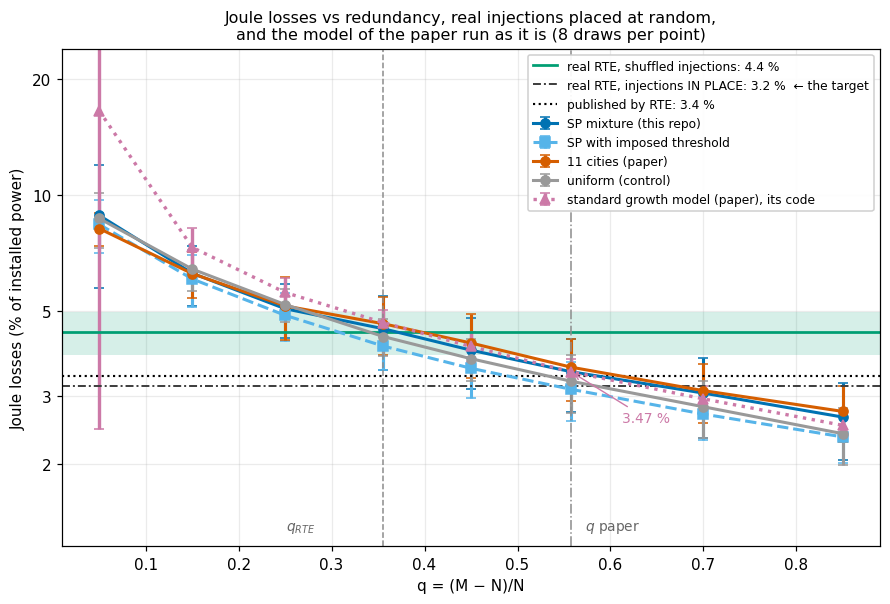

In [13]:
import matplotlib.ticker as mticker

RC_MAIN = "shuffle"          # the recipe of the notebook: real vector, neutral placement
vals = np.array([JOULE[(rc, m, round(float(q), 4))][0]
                 for rc in RECIPES for m in MODELS for q in Q_SWEEP]
                + [J_GM[round(float(q), 4)][0] for q in Q_SWEEP])
ylo, yhi = 0.75 * vals.min(), 1.45 * vals.max()
ticks = [t for t in (1, 2, 3, 5, 10, 20, 40, 80, 160) if ylo <= t <= yhi]


def _yerr(mu, sd):
    """Error bars clipped from below, the axis is logarithmic."""
    return np.vstack([np.minimum(sd, 0.85 * mu), sd])


fig, ax = plt.subplots(figsize=(8.2, 5.6))
mu_r, sd_r = REF_L[RC_MAIN]
ax.axhspan(mu_r - sd_r, mu_r + sd_r, color=C["ref"], alpha=.16, lw=0)

for m in MODELS:
    v = np.array([JOULE[(RC_MAIN, m, round(float(q), 4))] for q in Q_SWEEP])
    ax.errorbar(Q_SWEEP, v[:, 0], yerr=_yerr(v[:, 0], v[:, 1]),
                fmt="s--" if m == "SP20" else "o-",
                color=C[m], lw=2, ms=6, capsize=3, label=LBL[m])

# The standard growth model of the paper (fig. 6), as it is: its code, its
# injections sorted by node index, its voltages sorted by creation order, its
# own voltage spectrum. The three choices are locked together (see section 4),
# none can be taken without the others, so nothing is taken apart and we plot
# what the paper plots.
v = np.array([J_GM[round(float(q), 4)] for q in Q_SWEEP])
ax.errorbar(Q_SWEEP, v[:, 0], yerr=_yerr(v[:, 0], v[:, 1]), fmt="^:", color=C["warn"],
            lw=2.2, ms=7, capsize=3,
            label="standard growth model (paper), its code")

# the three horizontal references, in the legend rather than annotated
ax.axhline(mu_r, color=C["ref"], lw=1.8,
           label=f"real RTE, shuffled injections: {mu_r:.1f} %")
ax.axhline(REF_L["flow"], color="0.25", lw=1.3, ls=(0, (4, 1.5, 1, 1.5)),
           label=f"real RTE, injections IN PLACE: {REF_L['flow']:.1f} %  ← the target")
ax.axhline(pg.RTE_PUBLISHED_LOSS_PCT, color=C["rte"], lw=1.4, ls=":",
           label=f"published by RTE: {pg.RTE_PUBLISHED_LOSS_PCT:.1f} %")

ax.axvline(q_RTE, color="0.55", lw=1, ls="--")
ax.axvline(Q_PAPER, color="0.55", lw=1, ls="-.")
ax.set_yscale("log"); ax.set_ylim(ylo, yhi)
ax.yaxis.set_major_locator(mticker.FixedLocator(ticks))
ax.yaxis.set_minor_locator(mticker.NullLocator())
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel("q = (M − N)/N")
ax.set_ylabel("Joule losses (% of installed power)")
ax.grid(alpha=.25, which="both")
# labels of the vertical lines at the bottom (empty area)
ax.annotate("$q_{RTE}$", xy=(q_RTE, ylo * 1.10), xytext=(q_RTE - .105, ylo * 1.10),
            fontsize=9, color="0.4")
ax.annotate("$q$ paper", xy=(Q_PAPER, ylo * 1.10), xytext=(Q_PAPER + .015, ylo * 1.10),
            fontsize=9, color="0.4")
# the point on which the agreement of the paper rests
_kp = round(float(Q_PAPER), 4)
ax.annotate(f"{J_GM[_kp][0]:.2f} %", xy=(Q_PAPER, J_GM[_kp][0]),
            xytext=(Q_PAPER + .055, J_GM[_kp][0] * 0.74), fontsize=9,
            color=C["warn"],
            arrowprops=dict(arrowstyle="->", color=C["warn"], lw=.9))
ax.legend(fontsize=8, loc="upper right", framealpha=.93)
ax.set_title("Joule losses vs redundancy, real injections placed at random,\n"
             f"and the model of the paper run as it is ({N_RUNS} draws per point)",
             fontsize=10.5)
plt.tight_layout()
fig.savefig(ROOT / "out" / "06_joule_vs_q.pdf", bbox_inches="tight")
plt.show()

In [14]:
print(f"Joule losses at q = q_RTE = {q_RTE:.3f}   (% of installed power)\n")
print(f"{'':<28s}{'n_urban':>11s}" + "".join(f"{RSHORT[rc]:>18s}" for rc in RECIPES))
for m in MODELS:
    nu = np.mean([iu.sum() for _, iu in POS[m]])
    line = f"{LBL[m]:<28s}{nu:>11.0f}"
    for rc in RECIPES:
        mu, sd = JOULE[(rc, m, qk)]
        line += f"{mu:>11.2f} ±{sd:>5.2f}"
    print(line)
print("-" * (39 + 18 * len(RECIPES)))
line = f"{'real RTE topology':<28s}{'-':>11s}"
for rc in RECIPES:
    line += f"{REF_L[rc][0]:>11.2f} ±{REF_L[rc][1]:>5.2f}"
print(line + "   ← the reference")
print(f"{'  (injections in place)':<28s}{'-':>11s}{REF_L['flow']:>11.2f}")
print(f"{'  (published by RTE)':<28s}{'-':>11s}{pg.RTE_PUBLISHED_LOSS_PCT:>11.2f}")

print(f"\nstandard growth model of the paper, its code, its two queues, its spectrum")
print(f"  at q = q_RTE   = {q_RTE:.4f} : {J_GM[qk][0]:>5.2f} ± {J_GM[qk][1]:.2f} %"
      f"   ({(J_GM[qk][0]-pg.RTE_PUBLISHED_LOSS_PCT)/pg.RTE_PUBLISHED_LOSS_PCT:+.0%} "
      f"against the published value)")
_kp = round(float(Q_PAPER), 4)
print(f"  at q = q paper = {Q_PAPER:.4f} : {J_GM[_kp][0]:>5.2f} ± {J_GM[_kp][1]:.2f} %"
      f"   ({(J_GM[_kp][0]-pg.RTE_PUBLISHED_LOSS_PCT)/pg.RTE_PUBLISHED_LOSS_PCT:+.0%})"
      f"   ← the agreement of fig. 6")

print("\ngap to the real grid under the same recipe, in units of σ:")
for rc in RECIPES:
    mu_r, sd_r = REF_L[rc]
    line = f"  {RSHORT[rc]:<14s}: "
    for m in MODELS:
        mu, sd = JOULE[(rc, m, qk)]
        line += f"{m} {(mu - mu_r) / np.hypot(sd, sd_r):+.1f}σ   "
    print(line)

print("\neffect of the threshold, same fractal geometry (SP= against SP):")
for rc in RECIPES:
    a, b = JOULE[(rc, "SP", qk)], JOULE[(rc, "SP20", qk)]
    print(f"  {RSHORT[rc]:<14s}: {b[0]-a[0]:+.2f} pt  "
          f"({(b[0]-a[0])/np.hypot(a[1], b[1]):+.1f}σ)")
print("\neffect of the geometry, same number of urban nodes (SP= against 11 cities):")
for rc in RECIPES:
    a, b = JOULE[(rc, "ORI", qk)], JOULE[(rc, "SP20", qk)]
    print(f"  {RSHORT[rc]:<14s}: {b[0]-a[0]:+.2f} pt  "
          f"({(b[0]-a[0])/np.hypot(a[1], b[1]):+.1f}σ)")

Joule losses at q = q_RTE = 0.356   (% of installed power)

                                n_urban    P sorted/index        P shuffled
SP mixture (this repo)             1378       2.78 ± 0.60       4.49 ± 0.98
SP with imposed threshold           923       3.00 ± 0.52       4.05 ± 0.53
11 cities (paper)                   923       3.12 ± 0.39       4.63 ± 0.79
uniform (control)                     0       3.49 ± 0.51       4.29 ± 0.48
---------------------------------------------------------------------------
real RTE topology                     -       6.34 ± 0.00       4.41 ± 0.57   ← the reference
  (injections in place)               -       3.20
  (published by RTE)                  -       3.38

standard growth model of the paper, its code, its two queues, its spectrum
  at q = q_RTE   = 0.3558 :  4.66 ± 0.38 %   (+38% against the published value)
  at q = q paper = 0.5577 :  3.47 ± 0.27 %   (+3%)   ← the agreement of fig. 6

gap to the real grid under the same recipe, in units

- The growth model run with its own code gives 3.47 ± 0.27 % at its q = 0.5577
  (published 3.38 %), but 4.66 ± 0.38 % at q_RTE = 0.3558. The agreement relies on
  counting the 7 206 circuits instead of the 6 272 lines.
- Its two rules compensate. On the 11-city topology at q_RTE, sorted injections with
  flow-rank voltages give 3.12 %, shuffled injections 4.63 %, and the original rules
  (sorted injections, voltages by creation order) 4.66 %.
- With shuffled injections, losses do not separate the clouds: SP 4.49, SP= 4.05,
  11 cities 4.63, uniform 4.29 %, against 4.41 ± 0.57 % for the real topology
  (all within 0.5σ).
- With sorted injections: 2.78 / 3.00 / 3.12 / 3.49 %, against 3.20 % for the real grid
  with its injections in place. The uniform control is as close as the others.
- Neither the number of urban nodes (1 378 against 923, +49 %) nor the cluster shape
  moves the losses by more than 0.6σ.
- On the real grid, the position of each injection is worth 1.2 point (3.20 % in place,
  4.41 % shuffled).
- Losses drop by a factor 3 to 4 between q = 0.05 and 0.85, with the same slope for all
  clouds.


## 7. Where the losses are

`dc_losses` gives the loss of each line. Three breakdowns, independent of the node
numbering: (a) concentration (Lorenz curve, Gini), (b) voltage level, (c) line length.
The four clouds use the neutral placement. The growth model keeps its own spectrum and
voltage rule. Controls: 11 cities with sorted injections and flow-rank voltages, and the
sorted rule on the real grid.

loss profiles: 3 s


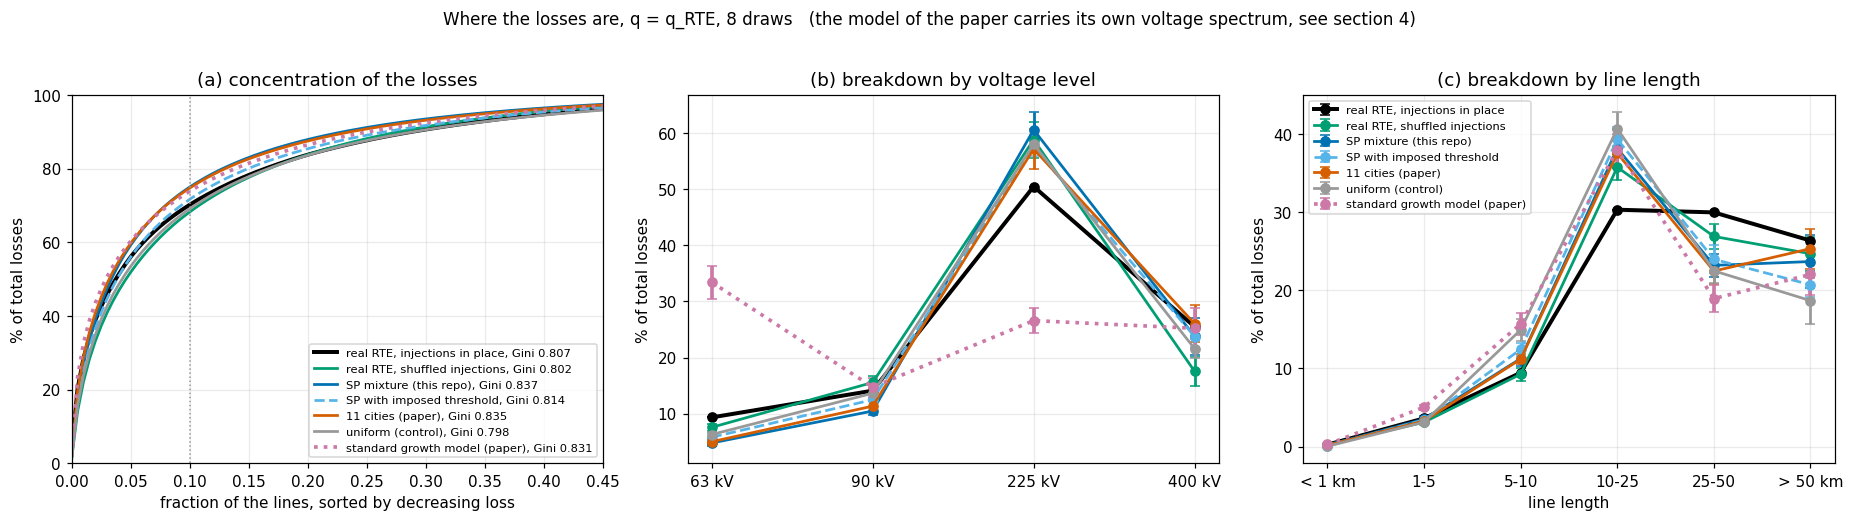

                                     Gini  top 10 %     63 kV     90 kV    225 kV    400 kV   < 1 km      1-5     5-10    10-25    25-50  > 50 km
real RTE, injections in place       0.807     70.2%       9.3      14.1      50.5      25.5      0.3      3.6      9.5     30.3     30.0     26.4
real RTE, shuffled injections       0.802     68.2%       7.6      15.6      58.8      17.6      0.2      3.1      9.3     35.8     26.9     24.7
SP mixture (this repo)              0.837     75.0%       4.8      10.5      60.6      23.8      0.2      3.5     11.3     38.2     23.2     23.7
SP with imposed threshold           0.814     71.7%       5.8      12.5      57.5      23.8      0.1      3.4     12.5     39.3     24.0     20.7
11 cities (paper)                   0.835     74.7%       5.0      11.4      57.2      26.0      0.2      3.3     11.2     37.6     22.5     25.3
uniform (control)                   0.798     69.1%       6.3      13.7      58.0      21.6      0.0      3.1     14.9     4

In [15]:
_cache_lp = CACHE / f"loss_profile_N{N_RTE}_R{N_RUNS}_v3.joblib"
LEV = np.unique(ref["volt_mix"])                      # the 7 real levels, 20 … 400 kV
LBINS = np.array([0, 1e3, 5e3, 1e4, 2.5e4, 5e4, np.inf])
LLAB = ["< 1 km", "1-5", "5-10", "10-25", "25-50", "> 50 km"]
XG = np.linspace(0, 1, 201)                           # common grid for the Lorenz curves


def _snap(U):
    """Map the model voltages (interpolated by quantiles) onto the 7 real levels."""
    return LEV[np.abs(np.log(U[:, None] / LEV[None, :])).argmin(1)]


def _profile(d):
    """Breakdown of the losses of a grid: Lorenz curve, by voltage, by length."""
    J, U, L = d["J"], _snap(d["U"]), d["L"]
    tot = J.sum()
    lor = np.interp(XG, np.arange(1, len(J) + 1) / len(J),
                    np.cumsum(np.sort(J)[::-1]) / tot)
    x = np.sort(J); n = len(J)
    return dict(lor=lor,
                volt=np.array([J[U == v].sum() for v in LEV]) / tot,
                leng=np.array([J[(L >= LBINS[i]) & (L < LBINS[i + 1])].sum()
                               for i in range(len(LLAB))]) / tot,
                gini=float((2 * np.arange(1, n + 1) - n - 1) @ x / (n * x.sum())),
                top10=float(np.interp(0.10, XG, lor)))


if _cache_lp.exists():
    LP = joblib.load(_cache_lp)
    print("loss profiles: loaded from cache")
else:
    t0 = time.time()
    LP = {m: [_profile(pg.dc_losses(NETS[m][qk][s], model_P(m, s, "shuffle"),
                                    ref["volt_mix"])) for s in range(N_RUNS)]
          for m in MODELS}
    # the model of the paper: its per-edge losses, computed by its own code,
    # hence with ITS voltage spectrum and ITS assignment queue
    LP["GM"] = [_profile(PAPER[(qk, s)]) for s in range(N_RUNS)]
    LP["RTEmix"] = [_profile(pg.dc_losses(G_rte, pg.injections_shuffled(ref["P"], s),
                                          ref["volt_mix"])) for s in range(N_RUNS)]
    LP["RTE"] = [_profile(pg.dc_losses(G_rte, ref["P"], ref["volt_mix"]))]
    # two controls, to separate what comes from the rule from the rest:
    #  - the "sorted" rule on the real grid, whose node index is arbitrary
    LP["RTEord"] = [_profile(pg.dc_losses(G_rte, P_ORDERED, ref["volt_mix"]))]
    #  - the topology of the paper with its sorted injections, but the estimator
    #    of the notebook (real spectrum of the 6 272 lines, voltages by flow rank)
    LP["ORIord"] = [_profile(pg.dc_losses(NETS["ORI"][qk][s], P_ORDERED,
                                          ref["volt_mix"])) for s in range(N_RUNS)]
    joblib.dump(LP, _cache_lp)
    print(f"loss profiles: {time.time()-t0:.0f} s")


def agg(k, f):
    v = np.array([d[f] for d in LP[k]])
    return v.mean(0), v.std(0)


SERIES = [("RTE", "real RTE, injections in place", C["rte"], "-", 2.6),
          ("RTEmix", "real RTE, shuffled injections", C["ref"], "-", 1.8),
          ("SP", LBL["SP"], C["SP"], "-", 1.8),
          ("SP20", LBL["SP20"], C["SP20"], "--", 1.8),
          ("ORI", LBL["ORI"], C["ORI"], "-", 1.8),
          ("RAND", LBL["RAND"], C["RAND"], "-", 1.8),
          ("GM", "standard growth model (paper)", C["warn"], ":", 2.4)]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

ax = axes[0]
for k, lab, col, ls, lw in SERIES:
    mu, _ = agg(k, "lor")
    g = np.mean([d["gini"] for d in LP[k]])
    ax.plot(XG, 100 * mu, ls, color=col, lw=lw, label=f"{lab}, Gini {g:.3f}")
ax.axvline(0.10, color="0.6", lw=1, ls=":")
ax.set_xlim(0, 0.45); ax.set_ylim(0, 100)
ax.set_xlabel("fraction of the lines, sorted by decreasing loss")
ax.set_ylabel("% of total losses")
ax.set_title("(a) concentration of the losses"); ax.legend(fontsize=7.5, loc="lower right")
ax.grid(alpha=.25)

ax = axes[1]
keep = [i for i, v in enumerate(LEV) if np.mean([d["volt"][i] for d in LP["RTE"]]) > 0.01]
xs = np.arange(len(keep))
for k, lab, col, ls, lw in SERIES:
    mu, sd = agg(k, "volt")
    ax.errorbar(xs, 100 * mu[keep], yerr=100 * sd[keep], fmt="o" + ls, color=col, lw=lw,
                ms=6, capsize=3, label=lab)
ax.set_xticks(xs); ax.set_xticklabels([f"{LEV[i]/1e3:.0f} kV" for i in keep])
ax.set_ylabel("% of total losses")
ax.set_title("(b) breakdown by voltage level"); ax.grid(alpha=.25)

ax = axes[2]
xs = np.arange(len(LLAB))
for k, lab, col, ls, lw in SERIES:
    mu, sd = agg(k, "leng")
    ax.errorbar(xs, 100 * mu, yerr=100 * sd, fmt="o" + ls, color=col, lw=lw, ms=6,
                capsize=3, label=lab)
ax.set_xticks(xs); ax.set_xticklabels(LLAB)
ax.set_xlabel("line length"); ax.set_ylabel("% of total losses")
ax.set_title("(c) breakdown by line length")
ax.legend(fontsize=7.5, loc="upper left"); ax.grid(alpha=.25)

fig.suptitle("Where the losses are, q = q_RTE, "
             f"{N_RUNS} draws   (the model of the paper carries its own voltage "
             "spectrum, see section 4)", fontsize=11, y=1.02)
plt.tight_layout()
fig.savefig(ROOT / "out" / "06_loss_breakdown.pdf", bbox_inches="tight")
plt.show()

TABLE = SERIES + [("ORIord", "11 cities, sorted injections", None, None, None),
                  ("RTEord", "real RTE, sorted injections", None, None, None)]
print(f"{'':<34s}{'Gini':>7s}{'top 10 %':>10s}" + "".join(
    f"{LEV[i]/1e3:>7.0f} kV" for i in keep) + "".join(f"{l:>9s}" for l in LLAB))
for k, lab, *_ in TABLE:
    mu_v, _ = agg(k, "volt"); mu_l, _ = agg(k, "leng")
    print(f"{lab:<34s}{np.mean([d['gini'] for d in LP[k]]):>7.3f}"
          f"{100*np.mean([d['top10'] for d in LP[k]]):>9.1f}%"
          + "".join(f"{100*mu_v[i]:>10.1f}" for i in keep)
          + "".join(f"{100*x:>9.1f}" for x in mu_l))

- **(a)** The 10 % most loaded lines carry 66 to 75 % of the losses everywhere (70.2 % for
  RTE, Gini 0.78 to 0.84). This comes from J ∝ P², not from geography.
- **(b)** The growth model puts 33.4 % of its losses on 63 kV (RTE: 9.3 %) and 26.6 % on
  225 kV (RTE: 50.5 %). At equal flow and length a 63 kV line loses 175 times more than a
  400 kV one, and its voltages are assigned by creation order. The same topology with
  sorted injections and flow-rank voltages gives 10.2 / 15.9 / 51.1 / 22.4 % against
  9.3 / 14.1 / 50.5 / 25.5 % for RTE.
- **(c)** All models lose too much on 10 to 25 km lines (37.3 to 40.7 % against 30.3 %)
  and too little on 25 to 50 km lines (18.9 to 24.0 % against 30.0 %), the energy
  counterpart of their too narrow length distribution.
- None of the breakdowns separates the cluster geometries.


## 8. Sensitivities

On the SP cloud at q = q_RTE: voltage rule, placement of the power plants, injection
recipe, and the population → load chain of the growth model with exponent κ.

In [16]:
_cache_s = CACHE / "sensitivity_v4.joblib"

if _cache_s.exists():
    SENS = joblib.load(_cache_s)
else:
    t0 = time.time()
    SENS = {}

    def _P_shuffle(s, model="SP"):
        """The default recipe of the notebook (section 6): real vector, neutral placement."""
        return pg.injections_shuffled(ref["P"], seed=s)

    def _P_load(s, model="SP", **kw):
        """Real load marginal reshuffled, the only one that exposes `prod_where`."""
        _, iu = POS[model][s]
        return pg.injections_marginal_load(ref["P_conso"], prod_pool, Ptot,
                                           seed=s, is_urban=iu, **kw)[0]

    def _P_kappa(s, kappa=0.0, model="SP", **kw):
        """The chain of the paper: assigned population, then load ∝ pop**kappa."""
        _, iu = POS[model][s]
        pop = pg.assign_population(iu, ld["pop_data"], seed=s)
        return pg.injections(pop, prod_pool, Ptot, seed=s, kappa=kappa,
                             is_urban=iu, **kw)[0]

    def _sweep(key, P_of_s, rule="flow", model="SP"):
        v = [pg.loss_pct(NETS[model][qk][s], P_of_s(s), Ptot, ref["volt_mix"],
                         voltage_rule=rule) for s in range(N_RUNS)]
        SENS[key] = (float(np.mean(v)), float(np.std(v)))

    for rule in ("flow", "time", "length", "random"):
        _sweep(("voltage", rule), _P_shuffle, rule=rule)
    for pw in ("random", "rural", "urban"):
        _sweep(("production", pw), lambda s, pw=pw: _P_load(s, prod_where=pw))

    # what modelling the load would cost, instead of taking the published vector
    _sweep(("recipe", "P shuffled"), _P_shuffle)
    _sweep(("recipe", "P sorted"), lambda s: P_ORDERED)
    _sweep(("recipe", "load reshuffled"), _P_load)
    for kappa in (0.0, 0.25, 0.5, 1.0):
        _sweep(("recipe", f"κ = {kappa}"), lambda s, k=kappa: _P_kappa(s, kappa=k))

    # κ = 1 is the only regime where geography becomes visible again, so the other
    # models and the reference are added there, otherwise the comparison has no judge
    for m in ("SP20", "ORI", "RAND"):
        _sweep(("κ = 1: other models", m),
               lambda s, m=m: _P_kappa(s, kappa=1.0, model=m), model=m)
    v = [pg.loss_pct(G_rte, pg.injections(pop_rte, prod_pool, Ptot, seed=s,
                                          kappa=1.0)[0], Ptot, ref["volt_mix"])
         for s in range(N_RUNS)]
    SENS[("κ = 1: other models", "real RTE")] = (float(np.mean(v)), float(np.std(v)))

    # cost of the κ = 0 flattening, measured without any model: real topology,
    # real production in place, only the consumption is replaced
    for lab, P in [("real load in place", ref["P"]),
                   ("flattened to its mean", ref["P_prod"] - ref["P_conso"].mean())]:
        SENS[("κ = 0 flattening", lab)] = (
            float(pg.loss_pct(G_rte, P, Ptot, ref["volt_mix"])), 0.0)

    # the two orderings of the paper, decoupled then coupled again
    _sweep(("ordering", "neutral + flow"), _P_shuffle, rule="flow")
    _sweep(("ordering", "neutral + queue"), _P_shuffle, rule="time")
    _sweep(("ordering", "sorted + flow"), lambda s: P_ORDERED, rule="flow")
    _sweep(("ordering", "sorted + queue"), lambda s: P_ORDERED, rule="time")
    joblib.dump(SENS, _cache_s)
    print(f"(sensitivities computed in {time.time()-t0:.0f} s)")

NOTE = {("voltage", "flow"): "default, sizing by flow",
        ("voltage", "time"): "sorted queue of the paper (creation order)",
        ("voltage", "length"): "longest line = highest voltage",
        ("voltage", "random"): "spectrum kept, correlation destroyed",
        ("production", "random"): "default, plants anywhere",
        ("production", "rural"): "plants in the random background",
        ("production", "urban"): "plants in the SP clusters",
        ("recipe", "P shuffled"): "default of section 6, published vector, neutral placement",
        ("recipe", "P sorted"): "section 6, published vector, assignment of the paper",
        ("recipe", "load reshuffled"): "real load marginal, random production",
        ("recipe", "κ = 0.0"): "chain of the paper, flat load",
        ("recipe", "κ = 0.25"): "",
        ("recipe", "κ = 0.5"): "",
        ("recipe", "κ = 1.0"): "load ∝ population metadata",
        ("κ = 1: other models", "SP20"): "SP with imposed threshold",
        ("κ = 1: other models", "ORI"): "11 cities (paper)",
        ("κ = 1: other models", "RAND"): "uniform control, no city",
        ("κ = 1: other models", "real RTE"): "← the judge",
        ("κ = 0 flattening", "real load in place"): "94 département steps",
        ("κ = 0 flattening", "flattened to its mean"): "what κ = 0 does",
        ("ordering", "neutral + flow"): "default",
        ("ordering", "neutral + queue"): "queue of the paper, unsorted injections",
        ("ordering", "sorted + flow"): "injections sorted as in the paper",
        ("ordering", "sorted + queue"): "both orderings of the paper, locked"}

TITLE = {"voltage": "VOLTAGE", "production": "PRODUCTION", "recipe": "INJECTION RECIPE",
         "κ = 1: other models": "AT κ = 1: THE OTHER MODELS",
         "κ = 0 flattening": "COST OF THE κ = 0 FLATTENING",
         "ordering": "INJECTION ORDERING × VOLTAGE RULE"}
cur = None
for (fam, var), (mu, sd) in SENS.items():
    if fam != cur:
        print(f"  {TITLE[fam]}"); cur = fam
    val = f"{mu:>7.2f} ± {sd:<6.2f}" if sd else f"{mu:>7.2f}        "
    print(f"    {var:<22s} {val}  {NOTE[(fam, var)]}")
print(f"\n  for reference, real RTE topology, default recipe (P shuffled): "
      f"{REF_L['shuffle'][0]:.2f} ± {REF_L['shuffle'][1]:.2f} %")

(sensitivities computed in 12 s)
  VOLTAGE
    flow                      4.49 ± 0.98    default, sizing by flow
    time                     40.48 ± 10.06   sorted queue of the paper (creation order)
    length                   30.89 ± 8.98    longest line = highest voltage
    random                  135.27 ± 35.89   spectrum kept, correlation destroyed
  PRODUCTION
    random                    4.85 ± 0.91    default, plants anywhere
    rural                     7.24 ± 2.75    plants in the random background
    urban                     5.95 ± 1.06    plants in the SP clusters
  INJECTION RECIPE
    P shuffled                4.49 ± 0.98    default of section 6, published vector, neutral placement
    P sorted                  2.78 ± 0.60    section 6, published vector, assignment of the paper
    load reshuffled           4.85 ± 0.91    real load marginal, random production
    κ = 0.0                   4.68 ± 0.88    chain of the paper, flat load
    κ = 0.25                  5.3

- Voltage rule: 4.5 % (flow rank), 40 % (creation order), 31 % (length), 135 % (random).
  It is the most sensitive choice.
- With sorted injections, the creation-order rule falls to 5.3 % against 2.8 % with the
  flow rank. The two queues of the growth model only work together.
- Plants in the rural background: +49 % (7.2 % against 4.9 %), in the SP clusters 6.0 %.
- Rebuilding the load: 4.9 % with the real consumption marginal, 4.7 % at κ = 0, then up
  to 13.4 % at κ = 1, with no defensible default. Section 6 therefore uses the published
  vector.
- At κ = 1 the clustered clouds reach 13.0 to 13.8 % and the uniform control 6.0 %
  (real topology 15.7 %). This is the only case where geography matters, and it rests on
  an assumed proportionality between load and population density.
- Replacing the 94 departmental consumption steps by their mean on the real grid costs
  +0.24 point (3.20 → 3.44 %).


## Results

1. The SP mixture gives losses close to the real grid: 2.78 ± 0.60 % (SP= 3.00 ± 0.52 %)
   with sorted injections and flow-rank voltages, against 3.20 % for the real grid
   (0.7σ) and 3.38 % published.
2. The growth model recovers 3.47 % at q = 0.5577, but 4.66 % at q_RTE, and through two
   rules that compensate (sorted injections −1.5 point, voltages by creation order
   +1.5 point).
3. The agreement is not geographic. The uniform control gives 3.49 % with the same rule,
   and the sorted rule on the real grid gives 6.34 %.
4. With shuffled injections, losses do not separate the clouds (within 0.5σ of the real
   topology). Total losses are not a test of the spatial model.
5. On the real grid, the position of the injections is worth 1.2 point (+38 %). The
   model reproduces this through node numbering, not geography.
6. The degree distribution separates clusters from no clusters (3 to 5 times the noise)
   and the SP mixture from the clouds with 20 % of urban nodes (twice the noise). It
   rejects all models against RTE (6 to 8 times the noise).
7. The breakdown by voltage rules out voltage assignment by creation order (33 % of the
   losses on 63 kV against 9 %).
8. With the log a calibration the urban fraction is 0.30 ± 0.04 and the 2PCF of the
   mixture has the amplitude of the data (a = 1.07). The former ρ calibration gave 0.17,
   biased low by its interpolation. With 1.5 times more urban nodes than `SP=`, the SP
   mixture still gives the same losses within 0.6σ.

Corrections for the growth model code: susceptance U²/X (done there implicitly),
voltages tied to the flow, the q of the comparison stated explicitly, and κ = 0 is a
departmental staircase (CV = 0.72), not a constant load.

Next steps: other observables (betweenness, flows against distance to the nearest
cluster), a model that produces the position ↔ injection coupling, and the same protocol
on ENEDIS.

In [17]:
rows = []
for m in MODELS:
    for rc in RECIPES:
        for q in Q_SWEEP:
            k = round(float(q), 4)
            mu, sd = JOULE[(rc, m, k)]
            Gs = NETS[m][k]
            rows.append(dict(
                model=m, label=LBL[m], recipe=rc, recipe_label=RSHORT[rc],
                q_target=k, q_measured=float(np.mean([pg.q_of(G) for G in Gs])),
                N=N_RTE, n_runs=N_RUNS,
                urban_frac=float(np.mean([iu.mean() for _, iu in POS[m]])),
                n_urban=float(np.mean([iu.sum() for _, iu in POS[m]])),
                L_tot_km=float(np.mean([pg.total_length_km(G) for G in Gs])),
                joule_pct=mu, joule_pct_std=sd))
for q in Q_SWEEP:                     # the model of the paper, run as it is
    k = round(float(q), 4)
    rows.append(dict(
        model="GM", label="standard growth model (paper)", recipe="paper",
        recipe_label="its code, its two queues", q_target=k, q_measured=k,
        N=N_RTE, n_runs=N_RUNS, urban_frac=np.nan, n_urban=np.nan,
        L_tot_km=float(np.mean([PAPER[(k, s_)]["L"].sum() / 1e3
                                for s_ in range(N_RUNS)])),
        joule_pct=J_GM[k][0], joule_pct_std=J_GM[k][1]))
for rc in RECIPES:
    rows.append(dict(model="RTE", label="real RTE topology", recipe=rc,
                     recipe_label=RSHORT[rc], q_target=np.nan, q_measured=q_RTE,
                     N=N_RTE, n_runs=N_RUNS, urban_frac=np.nan, n_urban=np.nan,
                     L_tot_km=pg.total_length_km(G_rte),
                     joule_pct=REF_L[rc][0], joule_pct_std=REF_L[rc][1]))
for lab, val in [("RTE, injections in place, real voltages", REF_L["given"]),
                 ("RTE, injections in place, voltages by flow", REF_L["flow"]),
                 ("value published by RTE", pg.RTE_PUBLISHED_LOSS_PCT)]:
    rows.append(dict(model="RTE", label=lab, recipe="-", recipe_label="-",
                     q_target=np.nan, q_measured=q_RTE, N=N_RTE, n_runs=1,
                     urban_frac=np.nan, n_urban=np.nan,
                     L_tot_km=pg.total_length_km(G_rte),
                     joule_pct=val, joule_pct_std=0.0))

df_out = pd.DataFrame(rows)
df_out.to_csv(ROOT / "out" / "06_powergrid_sp_joule.csv", index=False)

df_sens = pd.DataFrame([dict(family=f, variant=v, joule_pct=mu, joule_pct_std=sd,
                             note=NOTE[(f, v)])
                        for (f, v), (mu, sd) in SENS.items()])
df_sens.to_csv(ROOT / "out" / "06_powergrid_sp_sensitivity.csv", index=False)

df_deg = pd.DataFrame([dict(model=m, label=DLBL[m], tv_to_rte=TVR[m][0],
                            tv_to_rte_std=TVR[m][1], tv_intra=intra[m][0],
                            ratio=TVR[m][0] / intra[m][0],
                            **{f"pk_{l}": v for l, v in zip(KLAB, PK[m].mean(0))})
                       for m in DKEYS]
                      + [dict(model="RTE", label="real RTE", tv_to_rte=0.0,
                              tv_to_rte_std=0.0, tv_intra=np.nan, ratio=np.nan,
                              **{f"pk_{l}": v for l, v in zip(KLAB, PK["RTE"][0])})])
df_deg.to_csv(ROOT / "out" / "06_degrees.csv", index=False)

print("written:")
print("  out/06_powergrid_sp_joule.csv       ", df_out.shape)
print("  out/06_powergrid_sp_sensitivity.csv ", df_sens.shape)
print("  out/06_degrees.csv                  ", df_deg.shape)
for f in ("06_clouds", "06_2pcf", "06_topology", "06_degrees", "06_joule_vs_q",
          "06_loss_breakdown"):
    print(f"  out/{f}.pdf")
df_out[(df_out.q_target == qk)][["label", "recipe_label", "n_urban", "L_tot_km",
                                 "joule_pct", "joule_pct_std"]]

written:
  out/06_powergrid_sp_joule.csv        (77, 13)
  out/06_powergrid_sp_sensitivity.csv  (24, 5)
  out/06_degrees.csv                   (6, 15)
  out/06_clouds.pdf
  out/06_2pcf.pdf
  out/06_topology.pdf
  out/06_degrees.pdf
  out/06_joule_vs_q.pdf
  out/06_loss_breakdown.pdf


,label,recipe_label,n_urban,L_tot_km,joule_pct,joule_pct_std
3,SP mixture (this repo),P sorted/index,1377.625,73248.048975,2.781601,0.598293
11,SP mixture (this repo),P shuffled,1377.625,73248.048975,4.493064,0.983762
19,SP with imposed threshold,P sorted/index,923.375,76309.830841,2.996493,0.523362
27,SP with imposed threshold,P shuffled,923.375,76309.830841,4.050678,0.534930
35,11 cities (paper),P sorted/index,923.375,73458.874347,3.118114,0.385997
43,11 cities (paper),P shuffled,923.375,73458.874347,4.629212,0.786016
51,uniform (control),P sorted/index,0.000,78124.333902,3.487694,0.511366
59,uniform (control),P shuffled,0.000,78124.333902,4.287887,0.475229
67,standard growth model (paper),"its code, its two queues",NaN,73086.593210,4.659441,0.378521
